# Week 7: Comprehensive Model Evaluation
Final-Year B.Tech IT Project | AI-Based Resume Screening System

In [1]:
import os
import sys
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

eval_path = '../models/evaluation_results.pkl'
if os.path.exists(eval_path):
    with open(eval_path, 'rb') as f:
        eval_results = pickle.load(f)
else:
    sys.path.append(os.path.join('..', 'src'))
    from model_evaluator import evaluate_best_model
    eval_results = evaluate_best_model('../data', '../models')

metrics = eval_results['metrics']
print('=== PERFORMANCE METRICS ===')
for k, v in metrics.items():
    print(f'  {k}: {v}')

=== PERFORMANCE METRICS ===
  Accuracy: 0.895
  Precision: 0.8778
  Recall: 0.8876
  F1 Score: 0.8827
  ROC-AUC: 0.9615


### Confusion Matrix & ROC Curve
Visualizing classification performance on test set.

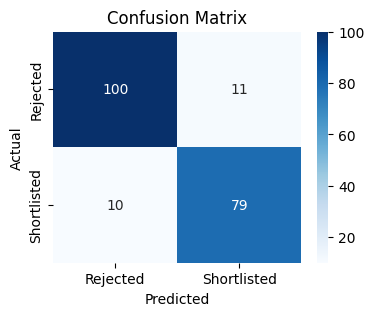

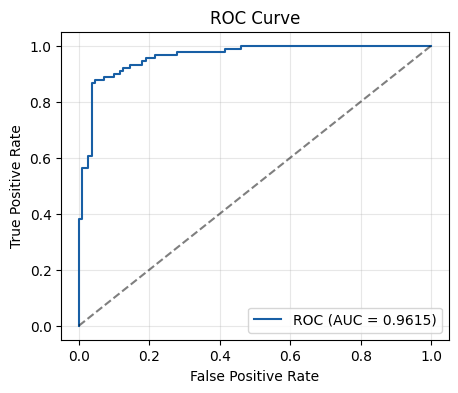

In [2]:
cm = np.array(eval_results['confusion_matrix'])
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected', 'Shortlisted'], yticklabels=['Rejected', 'Shortlisted'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

roc = eval_results['roc_curve']
plt.figure(figsize=(5, 4))
plt.plot(roc['fpr'], roc['tpr'], color='#185FA5', label=f'ROC (AUC = {metrics["ROC-AUC"]})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Top Feature Importances
Most influential features for shortlisting prediction.

C:\Rtemp\ipykernel_21840\3375616102.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df.head(10), x='Importance', y='Feature', palette='Blues_r')


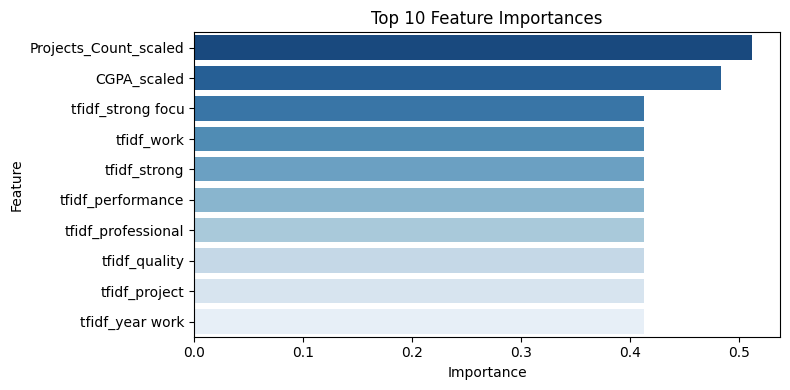

In [3]:
top_features = eval_results.get('top_features', eval_results.get('feature_importance', []))
imp_df = pd.DataFrame(top_features)
plt.figure(figsize=(8, 4))
sns.barplot(data=imp_df.head(10), x='Importance', y='Feature', palette='Blues_r')
plt.title('Top 10 Feature Importances')
plt.tight_layout()
plt.show()